# PIMSR 45x45 -> 90x90 Comparison

把 `origin.jpg`、`pimsr.bit`、`pimsr.hwh` 和這份 notebook 放在同一個 PYNQ 資料夾。

流程：
1. `origin.jpg` 用 bicubic resize 成 `90x90`，作為 reference。
2. `origin.jpg` 用 bicubic resize 成 `45x45`，作為 LR input。
3. `45x45` 用 bicubic resize 到 `90x90`，作為 bicubic baseline。
4. `45x45` 轉 YCbCr，Y 送進 PIMSR 硬體，Cb/Cr nearest neighbor resize，再轉回 RGB。
5. 主要 PSNR：把三張 90x90 圖都 bicubic 縮回 45x45，再和 `origin_bicubic_45x45.png` 比較。
6. 額外附上 90x90 reference PSNR：和 `origin_bicubic_90x90.png` 比較，方便看 SR 輸出在 90x90 空間的差異。

In [1]:
from pathlib import Path
import math
import time

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from pynq import Overlay, MMIO, Device

print('Current directory:', Path.cwd())
print('PYNQ devices:', Device.devices)
for p in sorted(Path.cwd().iterdir()):
    if p.suffix.lower() in {'.bit', '.hwh', '.jpg', '.jpeg', '.png', '.ipynb'}:
        print(' ', p.name)

Current directory: /home/xilinx/jupyter_notebooks/PIMSR
PYNQ devices: [<pynq.pl_server.embedded_device.EmbeddedDevice object at 0xace34850>]
  bicubic_45_to_90.png
  bicubic_45_to_90_then_bicubic_45x45.png
  cb_input.png
  cb_output.png
  cr_input.png
  cr_output.png
  input_45x45.png
  origin.jpg
  origin_bicubic_45x45.png
  origin_bicubic_90x90.png
  origin_bicubic_90x90_then_bicubic_45x45.png
  pimsr.bit
  pimsr.hwh
  pimsr_90x90_then_bicubic_45x45.png
  pimsr_compare_origin_45_90.ipynb
  pimsr_output_rgb_90x90.png
  pimsr_output_y_90x90.png
  pimsr_overlay_image_45x45.ipynb
  pimsr_overlay_smoke.ipynb
  y_input.png


In [2]:
BIT_FILE = 'pimsr.bit'
ORIGIN_IMAGE = 'origin.jpg'

REF_90 = 'origin_bicubic_90x90.png'
LR_45 = 'origin_bicubic_45x45.png'
BICUBIC_45_TO_90 = 'bicubic_45_to_90.png'
PIMSR_Y_90 = 'pimsr_output_y_90x90.png'
PIMSR_RGB_90 = 'pimsr_output_rgb_90x90.png'

IMG_W = 45
IMG_H = 45
SCALE = 2
OUT_W = IMG_W * SCALE
OUT_H = IMG_H * SCALE

REG_CONTROL = 0x00
REG_WIDTH = 0x04
REG_HEIGHT = 0x08
DONE_MASK = 1 << 1
BUSY_MASK = 1 << 2

CTRL_FALLBACK = 0x43C00000
LR_FALLBACK = 0x42000000
HR_FALLBACK = 0x40000000
CTRL_SIZE_FALLBACK = 0x10000
BRAM_SIZE_FALLBACK = 0x2000

HR_BYTES = OUT_W * OUT_H
assert HR_BYTES == 8100 and HR_BYTES <= 8192

In [3]:
def resample_bicubic():
    return getattr(getattr(Image, 'Resampling', Image), 'BICUBIC')


def resample_nearest():
    return getattr(getattr(Image, 'Resampling', Image), 'NEAREST')


def psnr_uint8(a, b):
    a = np.asarray(a, dtype=np.float64)
    b = np.asarray(b, dtype=np.float64)
    mse = np.mean((a - b) ** 2)
    if mse == 0:
        return float('inf')
    return 20.0 * math.log10(255.0 / math.sqrt(mse))


def rgb_to_y_array(img):
    if isinstance(img, np.ndarray):
        img = Image.fromarray(img.astype(np.uint8), mode='RGB')
    return np.asarray(img.convert('YCbCr').getchannel(0), dtype=np.uint8)


def pack_u8_to_u32_le(values):
    flat = np.asarray(values, dtype=np.uint8).reshape(-1)
    words = []
    for base in range(0, len(flat), 4):
        word = 0
        for lane, value in enumerate(flat[base:base + 4]):
            word |= int(value) << (8 * lane)
        words.append(word)
    return words


def unpack_u32_to_u8_le(words, nbytes):
    out = np.zeros(nbytes, dtype=np.uint8)
    idx = 0
    for word in words:
        for lane in range(4):
            if idx >= nbytes:
                break
            out[idx] = (int(word) >> (8 * lane)) & 0xFF
            idx += 1
    return out


def write_image_to_bram(mmio, image):
    for offset, word in enumerate(pack_u8_to_u32_le(image)):
        mmio.write(offset * 4, word)


def clear_bram(mmio, nbytes):
    for offset in range(0, nbytes, 4):
        mmio.write(offset, 0)


def read_image_from_bram(mmio, height, width):
    nbytes = height * width
    words = [mmio.read(offset) for offset in range(0, nbytes, 4)]
    return unpack_u32_to_u8_le(words, nbytes).reshape(height, width)


def wait_done(ctrl, timeout_s=2.0):
    deadline = time.monotonic() + timeout_s
    last_status = 0
    while time.monotonic() < deadline:
        last_status = ctrl.read(REG_CONTROL)
        if last_status & DONE_MASK:
            return last_status
        time.sleep(0.001)
    raise TimeoutError(
        f'PIMSR timeout: status=0x{last_status:08x}, '
        f'done={(last_status & DONE_MASK) != 0}, busy={(last_status & BUSY_MASK) != 0}'
    )

Saved reference: origin_bicubic_90x90.png
Saved LR input : origin_bicubic_45x45.png
Saved bicubic  : bicubic_45_to_90.png
LR Y stats: (45, 45) 30 223 361769


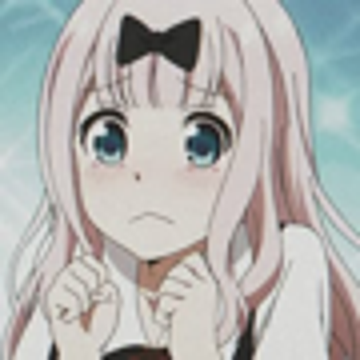

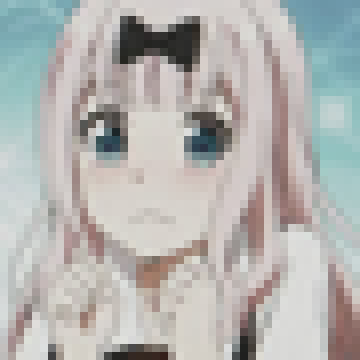

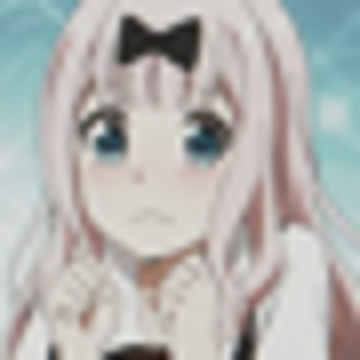

In [4]:
origin_path = Path(ORIGIN_IMAGE)
assert origin_path.exists(), f'Missing {origin_path}'

origin = Image.open(origin_path).convert('RGB')
ref_90_img = origin.resize((OUT_W, OUT_H), resample_bicubic())
lr_45_img = origin.resize((IMG_W, IMG_H), resample_bicubic())
bicubic_90_img = lr_45_img.resize((OUT_W, OUT_H), resample_bicubic())

ref_90_img.save(REF_90)
lr_45_img.save(LR_45)
bicubic_90_img.save(BICUBIC_45_TO_90)

lr_y, lr_cb, lr_cr = lr_45_img.convert('YCbCr').split()
lr_y = np.asarray(lr_y, dtype=np.uint8)
lr_cb = np.asarray(lr_cb, dtype=np.uint8)
lr_cr = np.asarray(lr_cr, dtype=np.uint8)

print('Saved reference:', REF_90)
print('Saved LR input :', LR_45)
print('Saved bicubic  :', BICUBIC_45_TO_90)
print('LR Y stats:', lr_y.shape, int(lr_y.min()), int(lr_y.max()), int(lr_y.sum()))
display(ref_90_img.resize((360, 360)))
display(lr_45_img.resize((360, 360), resample_nearest()))
display(bicubic_90_img.resize((360, 360)))

In [5]:
bit_path = Path(BIT_FILE)
assert bit_path.exists(), f'Missing {bit_path}'
assert bit_path.with_suffix('.hwh').exists(), 'Missing matching .hwh file'

overlay = Overlay(str(bit_path))
print('Overlay loaded')
for name, info in overlay.ip_dict.items():
    addr = info.get('phys_addr')
    size = info.get('addr_range')
    if addr is not None:
        print(f'  {name}: base=0x{addr:08x}, range=0x{size:x}')

Overlay loaded
  pimsr_axi_ip_0: base=0x43c00000, range=0x10000


In [6]:
def find_address(name_contains):
    matches = []
    for d in [overlay.ip_dict, getattr(overlay, 'mem_dict', {})]:
        for name, info in d.items():
            if name_contains.lower() in name.lower() and 'phys_addr' in info:
                matches.append((name, info['phys_addr'], info.get('addr_range', 0)))
    if len(matches) != 1:
        raise RuntimeError(f'Expected one match for {name_contains!r}, got {matches}')
    return matches[0]


try:
    ctrl_name, CTRL_BASE, CTRL_SIZE = find_address('pimsr_axi_ip')
except RuntimeError:
    ctrl_name, CTRL_BASE, CTRL_SIZE = 'manual_pimsr_axi_ip', CTRL_FALLBACK, CTRL_SIZE_FALLBACK

try:
    lr_name, LR_BASE, LR_SIZE = find_address('lr_bram_BRAM_PORTA')
except RuntimeError:
    lr_name, LR_BASE, LR_SIZE = 'manual_lr_bram', LR_FALLBACK, BRAM_SIZE_FALLBACK

try:
    hr_name, HR_BASE, HR_SIZE = find_address('hr_bram_BRAM_PORTA')
except RuntimeError:
    hr_name, HR_BASE, HR_SIZE = 'manual_hr_bram', HR_FALLBACK, BRAM_SIZE_FALLBACK

print(f'Using CTRL: {ctrl_name} @ 0x{CTRL_BASE:08x}, size=0x{CTRL_SIZE:x}')
print(f'Using LR  : {lr_name} @ 0x{LR_BASE:08x}, size=0x{LR_SIZE:x}')
print(f'Using HR  : {hr_name} @ 0x{HR_BASE:08x}, size=0x{HR_SIZE:x}')

ctrl = MMIO(CTRL_BASE, CTRL_SIZE)
lr = MMIO(LR_BASE, LR_SIZE)
hr = MMIO(HR_BASE, HR_SIZE)

print('Initial status:', hex(ctrl.read(REG_CONTROL)))
print('Width register:', ctrl.read(REG_WIDTH))
print('Height register:', ctrl.read(REG_HEIGHT))

Using CTRL: pimsr_axi_ip_0 @ 0x43c00000, size=0x10000
Using LR  : lr_bram_BRAM_PORTA @ 0x42000000, size=0x2000
Using HR  : hr_bram_BRAM_PORTA @ 0x40000000, size=0x2000
Initial status: 0x0
Width register: 45
Height register: 45


Done status: 0x2
Saved PIMSR Y  : pimsr_output_y_90x90.png
Saved PIMSR RGB: pimsr_output_rgb_90x90.png
PIMSR Y stats: (90, 90) 8 234 1433434


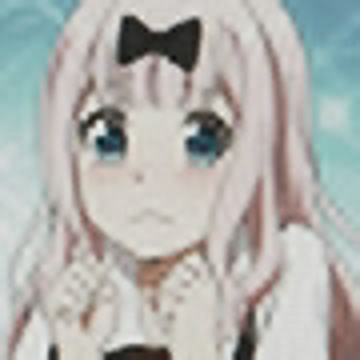

In [7]:
write_image_to_bram(lr, lr_y)
clear_bram(hr, HR_BYTES)

ctrl.write(REG_WIDTH, IMG_W)
ctrl.write(REG_HEIGHT, IMG_H)
ctrl.write(REG_CONTROL, 1)
status = wait_done(ctrl, timeout_s=2.0)
print('Done status:', hex(status))

pimsr_y = read_image_from_bram(hr, OUT_H, OUT_W)
Image.fromarray(pimsr_y, mode='L').save(PIMSR_Y_90)

cb_90 = np.asarray(Image.fromarray(lr_cb, mode='L').resize((OUT_W, OUT_H), resample_nearest()), dtype=np.uint8)
cr_90 = np.asarray(Image.fromarray(lr_cr, mode='L').resize((OUT_W, OUT_H), resample_nearest()), dtype=np.uint8)
pimsr_rgb_img = Image.merge(
    'YCbCr',
    (Image.fromarray(pimsr_y, mode='L'), Image.fromarray(cb_90, mode='L'), Image.fromarray(cr_90, mode='L')),
).convert('RGB')
pimsr_rgb_img.save(PIMSR_RGB_90)

print('Saved PIMSR Y  :', PIMSR_Y_90)
print('Saved PIMSR RGB:', PIMSR_RGB_90)
print('PIMSR Y stats:', pimsr_y.shape, int(pimsr_y.min()), int(pimsr_y.max()), int(pimsr_y.sum()))
display(pimsr_rgb_img.resize((360, 360)))

Image.fromarray(cb_90).save('cb_output.png')
Image.fromarray(cr_90).save('cr_output.png')
Image.fromarray(lr_y).save('y_input.png')
Image.fromarray(lr_cb).save('cb_input.png')
Image.fromarray(lr_cr).save('cr_input.png')

Requested PSNR: compare against origin bicubic -> 45x45
bicubic_origin45_to_90_then_back45       RGB_PSNR=  34.5689 dB   Y_PSNR=  34.6096 dB
bicubic_origin90_then_back45             RGB_PSNR=  50.5705 dB   Y_PSNR=  50.5994 dB
pimsr_hardware90_then_back45             RGB_PSNR=  37.7915 dB   Y_PSNR=  38.8924 dB

Extra PSNR: compare against origin bicubic -> 90x90
origin_bicubic_90x90_reference           RGB_PSNR=      inf dB   Y_PSNR=      inf dB
bicubic_origin45_to_90                   RGB_PSNR=  24.8130 dB   Y_PSNR=  24.8318 dB
pimsr_hardware_45_to_90                  RGB_PSNR=  25.9773 dB   Y_PSNR=  26.1121 dB


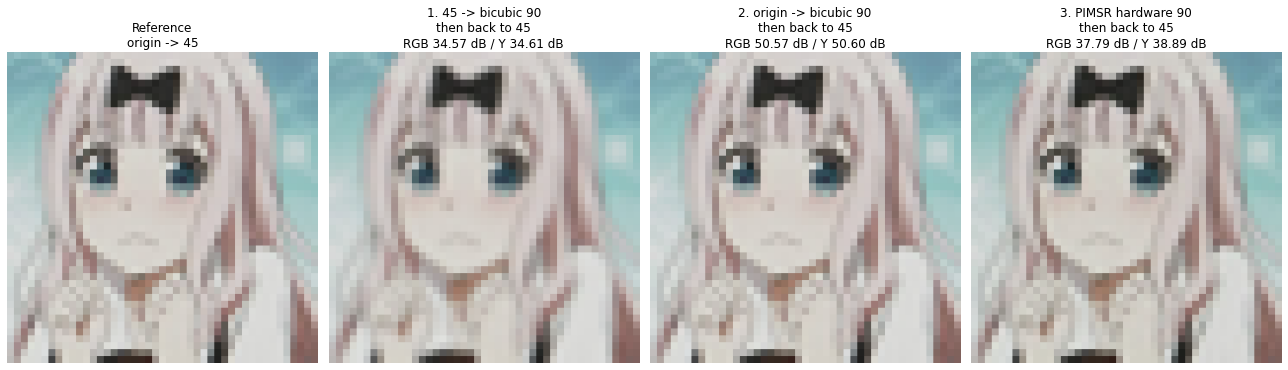

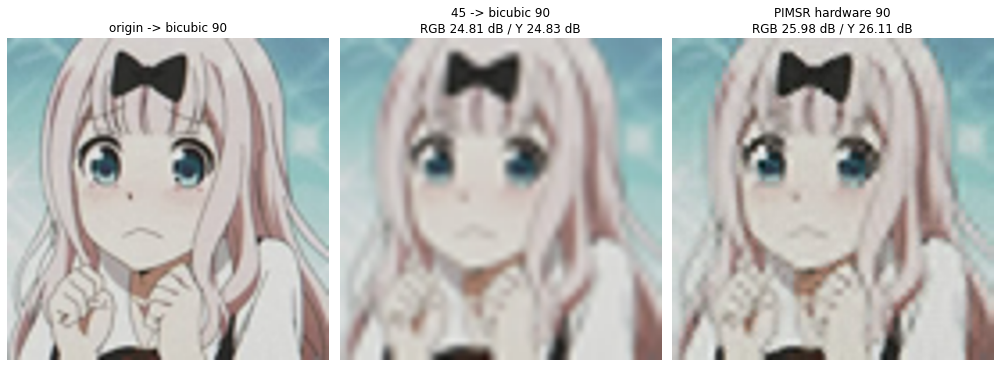

In [8]:
ref90_rgb = np.asarray(ref_90_img, dtype=np.uint8)
lr45_ref_rgb = np.asarray(lr_45_img, dtype=np.uint8)
bicubic90_rgb = np.asarray(bicubic_90_img, dtype=np.uint8)
pimsr90_rgb = np.asarray(pimsr_rgb_img, dtype=np.uint8)

# 你指定的比較：三張 90x90 圖都先 bicubic 縮回 45x45，再和 origin->45x45 比。
origin90_to45_img = ref_90_img.resize((IMG_W, IMG_H), resample_bicubic())
bicubic90_to45_img = bicubic_90_img.resize((IMG_W, IMG_H), resample_bicubic())
pimsr90_to45_img = pimsr_rgb_img.resize((IMG_W, IMG_H), resample_bicubic())

origin90_to45_img.save('origin_bicubic_90x90_then_bicubic_45x45.png')
bicubic90_to45_img.save('bicubic_45_to_90_then_bicubic_45x45.png')
pimsr90_to45_img.save('pimsr_90x90_then_bicubic_45x45.png')

lr45_ref_y = rgb_to_y_array(lr_45_img)
rows_45_ref = [
    {
        'image': 'bicubic_origin45_to_90_then_back45',
        'reference': LR_45,
        'rgb_psnr_db': psnr_uint8(lr45_ref_rgb, np.asarray(bicubic90_to45_img, dtype=np.uint8)),
        'y_psnr_db': psnr_uint8(lr45_ref_y, rgb_to_y_array(bicubic90_to45_img)),
    },
    {
        'image': 'bicubic_origin90_then_back45',
        'reference': LR_45,
        'rgb_psnr_db': psnr_uint8(lr45_ref_rgb, np.asarray(origin90_to45_img, dtype=np.uint8)),
        'y_psnr_db': psnr_uint8(lr45_ref_y, rgb_to_y_array(origin90_to45_img)),
    },
    {
        'image': 'pimsr_hardware90_then_back45',
        'reference': LR_45,
        'rgb_psnr_db': psnr_uint8(lr45_ref_rgb, np.asarray(pimsr90_to45_img, dtype=np.uint8)),
        'y_psnr_db': psnr_uint8(lr45_ref_y, rgb_to_y_array(pimsr90_to45_img)),
    },
]

# 額外參考：三張 90x90 圖直接和 origin->90x90 比。
ref90_y = rgb_to_y_array(ref_90_img)
rows_90_ref = [
    {'image': 'origin_bicubic_90x90_reference', 'reference': REF_90, 'rgb_psnr_db': float('inf'), 'y_psnr_db': float('inf')},
    {'image': 'bicubic_origin45_to_90', 'reference': REF_90, 'rgb_psnr_db': psnr_uint8(ref90_rgb, bicubic90_rgb), 'y_psnr_db': psnr_uint8(ref90_y, rgb_to_y_array(bicubic_90_img))},
    {'image': 'pimsr_hardware_45_to_90', 'reference': REF_90, 'rgb_psnr_db': psnr_uint8(ref90_rgb, pimsr90_rgb), 'y_psnr_db': psnr_uint8(ref90_y, rgb_to_y_array(pimsr_rgb_img))},
]

def print_rows(title, rows):
    print(title)
    for row in rows:
        rgb = row['rgb_psnr_db']
        y = row['y_psnr_db']
        rgb_s = 'inf' if math.isinf(rgb) else f'{rgb:.4f}'
        y_s = 'inf' if math.isinf(y) else f'{y:.4f}'
        print(f"{row['image']:40s} RGB_PSNR={rgb_s:>9s} dB   Y_PSNR={y_s:>9s} dB")


print_rows('Requested PSNR: compare against origin bicubic -> 45x45', rows_45_ref)
print()
print_rows('Extra PSNR: compare against origin bicubic -> 90x90', rows_90_ref)

show_items = [
    ('Reference\norigin -> 45', lr_45_img.resize((360, 360), resample_nearest()), None),
    ('1. 45 -> bicubic 90\nthen back to 45', bicubic90_to45_img.resize((360, 360), resample_nearest()), rows_45_ref[0]),
    ('2. origin -> bicubic 90\nthen back to 45', origin90_to45_img.resize((360, 360), resample_nearest()), rows_45_ref[1]),
    ('3. PIMSR hardware 90\nthen back to 45', pimsr90_to45_img.resize((360, 360), resample_nearest()), rows_45_ref[2]),
]

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, (title, img, row) in zip(axes, show_items):
    ax.imshow(img)
    ax.axis('off')
    if row is None:
        ax.set_title(title)
    else:
        ax.set_title(f"{title}\nRGB {row['rgb_psnr_db']:.2f} dB / Y {row['y_psnr_db']:.2f} dB")
plt.tight_layout()
plt.show()

show90_items = [
    ('origin -> bicubic 90', ref_90_img.resize((360, 360)), None),
    ('45 -> bicubic 90', bicubic_90_img.resize((360, 360)), rows_90_ref[1]),
    ('PIMSR hardware 90', pimsr_rgb_img.resize((360, 360)), rows_90_ref[2]),
]

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
for ax, (title, img, row) in zip(axes, show90_items):
    ax.imshow(img)
    ax.axis('off')
    if row is None:
        ax.set_title(title)
    else:
        ax.set_title(f"{title}\nRGB {row['rgb_psnr_db']:.2f} dB / Y {row['y_psnr_db']:.2f} dB")
plt.tight_layout()
plt.show()